In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import csv

# --------------------------------------------------
# 1. Read data from CSV
# --------------------------------------------------
with open(
    '/mnt/CEPH_PROJECTS/provinzBZ_risk_EO/GlacierOutlines/results_dynamicThresh/glacier_area_wide_v0.3_full_minPatch10000_hole1.csv',
    newline=''
) as File:

    lines = csv.reader(File, delimiter=',')

    x = np.array([int(year) for year in next(lines)[2:]])

    y1 = [float(v) for v in next(lines)[2:]]
    y2 = [float(v) for v in next(lines)[2:]]
    y3 = [float(v) for v in next(lines)[2:]]
    y4 = [float(v) for v in next(lines)[2:]]
    y5 = [float(v) for v in next(lines)[2:]]
    y6 = [float(v) for v in next(lines)[2:]]

west_ref_years = np.array([2016, 2023])
west_ref_areas = np.array([67.923, 57.982])
east_ref_years = np.array([2017, 2023])
east_ref_areas = np.array([17.802, 14.108])

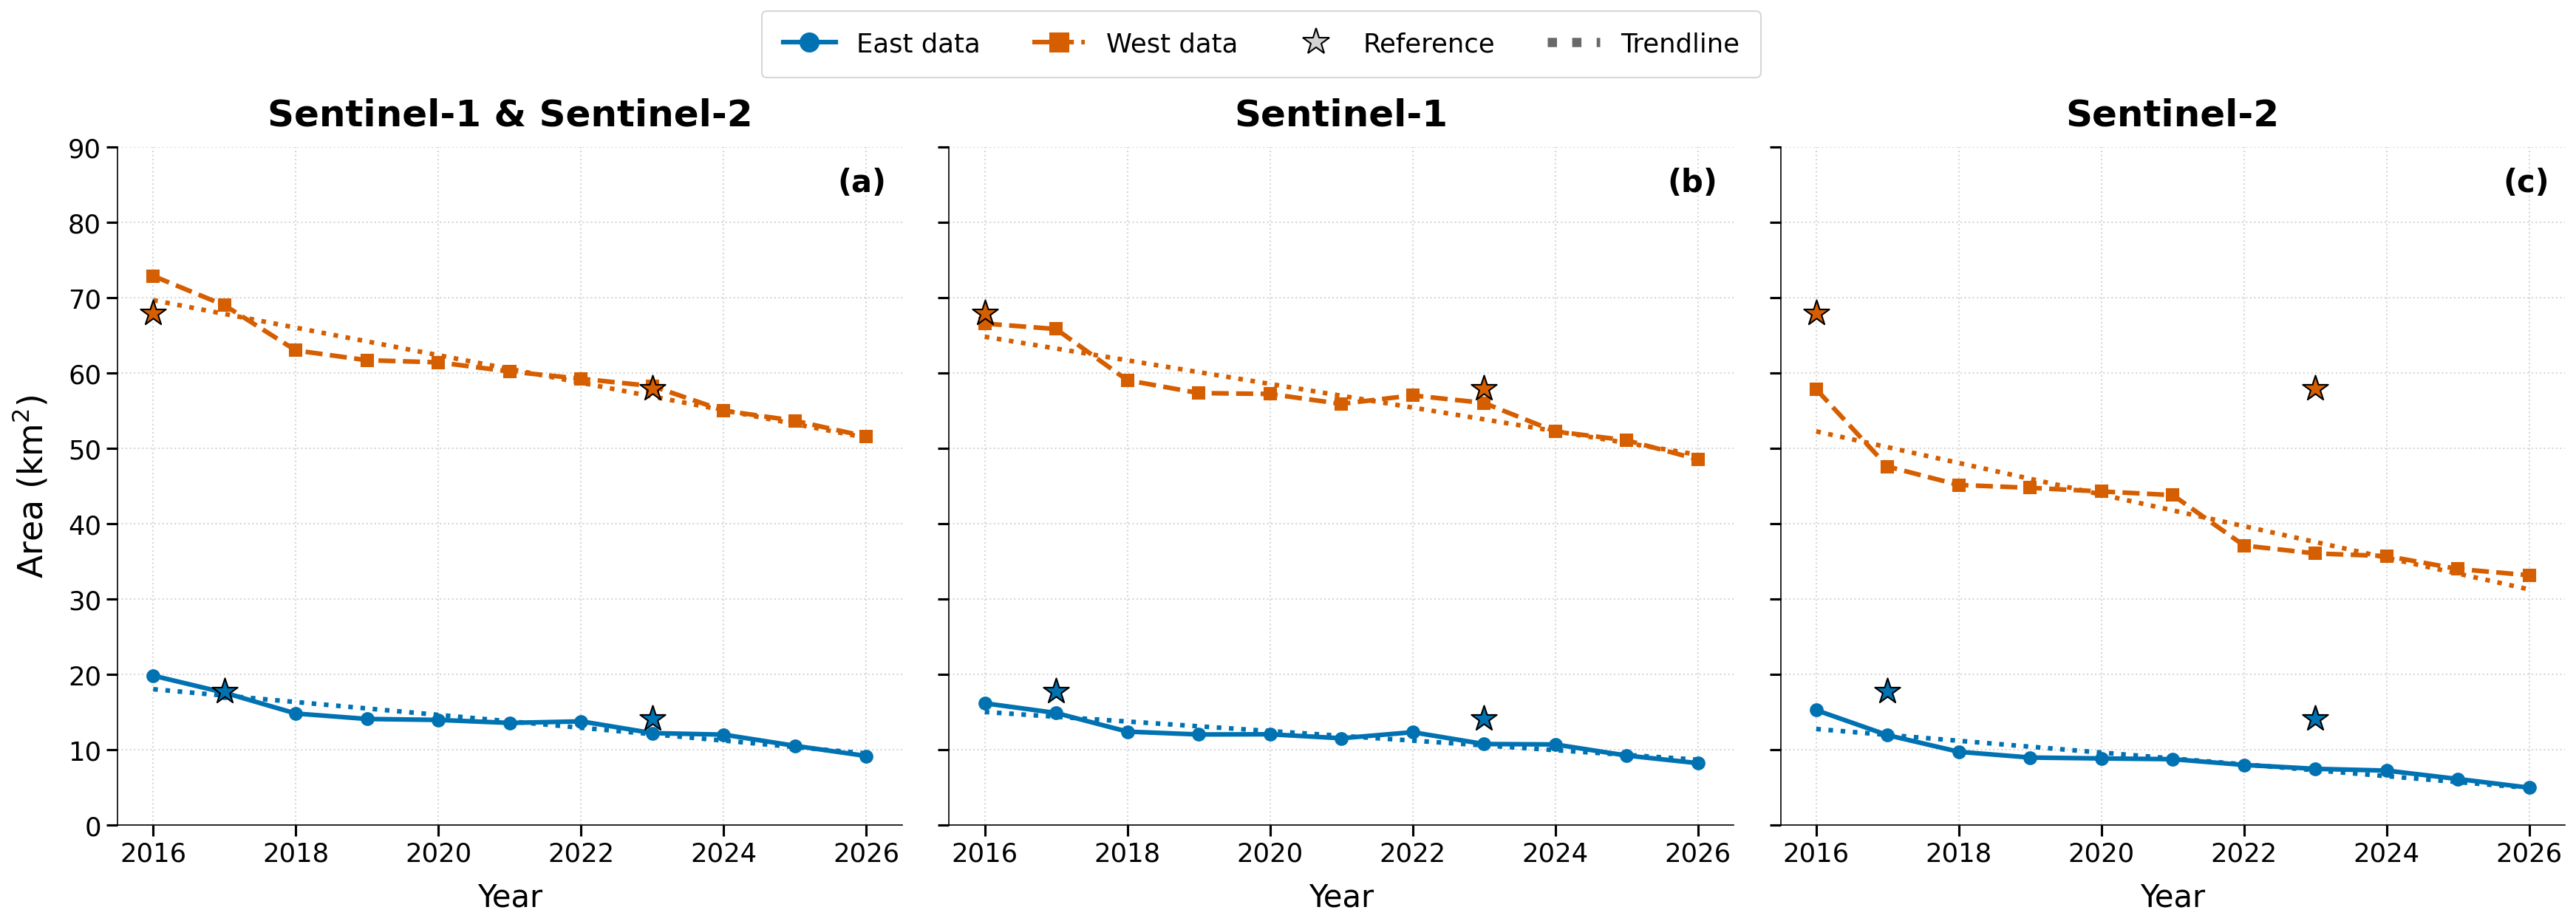

Sentinel-1 & Sentinel-2: East decrease = 0.853, West decrease = 1.826
Sentinel-1: East decrease = 0.634, West decrease = 1.567
Sentinel-2: East decrease = 0.783, West decrease = 2.098
East reference decrease: 0.616
West reference decrease: 1.420


In [7]:
from matplotlib.lines import Line2D

# 1. Settings
COL_EAST, COL_WEST = '#0072B2', '#D55E00'
panels = [  # (title, east series, west series)
    ('Sentinel-1 & Sentinel-2', y1, y2),
    ('Sentinel-1',              y3, y4),
    ('Sentinel-2',              y5, y6),
]

# Common y-range (incl. references, with headroom for panel letters); or set manually
all_vals = np.concatenate([y1, y2, y3, y4, y5, y6, west_ref_areas, east_ref_areas])
Y_MIN, Y_MAX = 0, np.ceil(all_vals.max() / 10) * 10 + 10
x_min, x_max = min(min(x), 2016), max(max(x), 2026)

# 2. Figure: 1 row x 3 columns, shared axes
fig, axes = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(24, 9), dpi=150,
                         gridspec_kw={'wspace': 0.06})
fig.subplots_adjust(left=0.07, right=0.99, top=0.84, bottom=0.16)

# 3. Plot each panel
rates = {}
for i, (ax, (title, east, west)) in enumerate(zip(axes, panels)):
    rates[title] = []
    for y, ry, ra, c, ls, m in [(east, east_ref_years, east_ref_areas, COL_EAST, '-',  'o'),
                                (west, west_ref_years, west_ref_areas, COL_WEST, '--', 's')]:
        trend = np.polyfit(x, y, 1)
        rates[title].append(-trend[0])
        ax.plot(x, y, color=c, ls=ls, lw=3, marker=m, ms=8)
        ax.plot(x, np.polyval(trend, x), color=c, ls=':', lw=3)
        ax.scatter(ry, ra, color=c, marker='*', s=300, edgecolor='k', lw=1, zorder=5)

    ax.set_title(title, fontsize=24, fontweight='bold', pad=14)
    ax.text(0.98, 0.97, f'({"abc"[i]})', transform=ax.transAxes,
            fontsize=20, fontweight='bold', ha='right', va='top')
    ax.set_ylim(Y_MIN, Y_MAX)
    ax.set_xlim(x_min - 0.5, x_max + 0.5)
    ax.set_xticks(range(x_min, x_max + 1, 2))
    ax.set_xlabel('Year', fontsize=20, labelpad=10)
    ax.tick_params(axis='both', labelsize=17, length=7, width=1.5)
    ax.grid(True, ls=':', lw=1, alpha=0.5)
    ax.spines[['top', 'right']].set_visible(False)

axes[0].set_ylabel(r'Area (km$^2$)', fontsize=22, labelpad=12)

# 4. Legend
handles = [
    Line2D([0], [0], color=COL_EAST, ls='-',  lw=3, marker='o', ms=12, label='East data'),
    Line2D([0], [0], color=COL_WEST, ls='--', lw=3, marker='s', ms=12, label='West data'),
    Line2D([0], [0], marker='*', ls='None', ms=18, mfc='lightgray', mec='k', mew=1, label='Reference'),
    Line2D([0], [0], color='dimgray', ls=':', lw=6, label='Trendline'),
]
fig.legend(handles=handles, fontsize=17, loc='upper center', ncol=4,
           bbox_to_anchor=(0.5, 0.99), frameon=True, borderpad=0.8, columnspacing=2)

fig.savefig('/mnt/CEPH_PROJECTS/provinzBZ_risk_EO/GlacierOutlines/results_test/'
             'sentinel_3panel_outlines_v0.2.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# 5. Annual decrease rates (km²/yr)
for title, (e, w) in rates.items():
    print(f'{title}: East decrease = {e:.3f}, West decrease = {w:.3f}')
for name, yrs, areas in [('East', east_ref_years, east_ref_areas), ('West', west_ref_years, west_ref_areas)]:
    print(f'{name} reference decrease: {-np.polyfit(yrs, areas, 1)[0]:.3f}')

In [ ]:
from matplotlib.lines import Line2D

# 1. Figure with broken y-axis
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, sharex=True, figsize=(14, 9), dpi=150)
fig.subplots_adjust(left=0.12, right=0.97, top=0.90, bottom=0.10, hspace=0.05)

# 2. One config row per panel: axis, data, reference data, colour, linestyle, marker, name
panels = [
    (ax_top,    y2, west_ref_years, west_ref_areas, '#D55E00', '--', 's', 'West data'),
    (ax_bottom, y1, east_ref_years, east_ref_areas, '#0072B2', '-',  'o', 'East data'),
]

handles, decrease = [], {}
for ax, y, ry, ra, c, ls, m, name in panels:
    slope = np.polyfit(x, y, 1)
    ax.plot(x, y, color=c, ls=ls, lw=3, marker=m, ms=8)                  # data
    ax.plot(x, np.polyval(slope, x), color=c, ls=':', lw=3)             # trend
    ax.scatter(ry, ra, color=c, marker='*', s=300, edgecolor='k', lw=1, zorder=5)  # reference
    decrease[name] = -slope[0]
    decrease[name.replace('data', 'reference')] = -np.polyfit(ry, ra, 1)[0]
    handles.append(Line2D([0], [0], color=c, ls=ls, lw=3, marker=m, ms=8, label=name))

# 3. Axis limits, ticks, grid, spines
ax_top.set_ylim(40, 75)
ax_bottom.set_ylim(5, 25)
x0, x1 = min(min(x), 2016), max(max(x), 2026)
ax_bottom.set_xticks(range(x0, x1 + 1))
ax_bottom.set_xlim(x0 - 0.5, x1 + 0.5)

for ax in (ax_top, ax_bottom):
    ax.tick_params(axis='both', labelsize=18, length=7, width=1.5)
    ax.grid(True, ls=':', lw=1, alpha=0.5)
    ax.spines[['top', 'right']].set_visible(False)
ax_top.spines['bottom'].set_visible(False)
ax_top.tick_params(axis='x', bottom=False, labelbottom=False)

# 4. Diagonal break marks
d = 0.012
for ax, ys in ((ax_top, (-d, d)), (ax_bottom, (1 - d, 1 + d))):
    for xs in ((-d, d), (1 - d, 1 + d)):
        ax.plot(xs, ys, transform=ax.transAxes, color='k', clip_on=False, lw=1)

# 5. Labels and legend
ax_top.set_title('Sentinel-1 & Sentinel-2 Outlines', fontsize=27, fontweight='bold', pad=18)
ax_bottom.set_xlabel('Year', fontsize=22, labelpad=12)
fig.supylabel(r'Area (km$^2$)', fontsize=22, x=0.04)

handles += [
    Line2D([0], [0], marker='*', ls='None', ms=18, mfc='lightgray', mec='k', mew=1, label='Reference'),
    Line2D([0], [0], color='dimgray', ls=':', lw=3, label='Trendline'),
]
fig.legend(handles=handles, fontsize=14, loc='upper right', bbox_to_anchor=(0.96, 0.91),
           frameon=True, borderpad=0.8, labelspacing=0.7)

# fig.savefig('/mnt/CEPH_PROJECTS/provinzBZ_risk_EO/GlacierOutlines/results_test/'
#             'sentinelCombined_full_outlines_poster.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# 6. Annual decrease rates
for name, val in decrease.items():
    print(f'{name.capitalize()} decrease:', val)

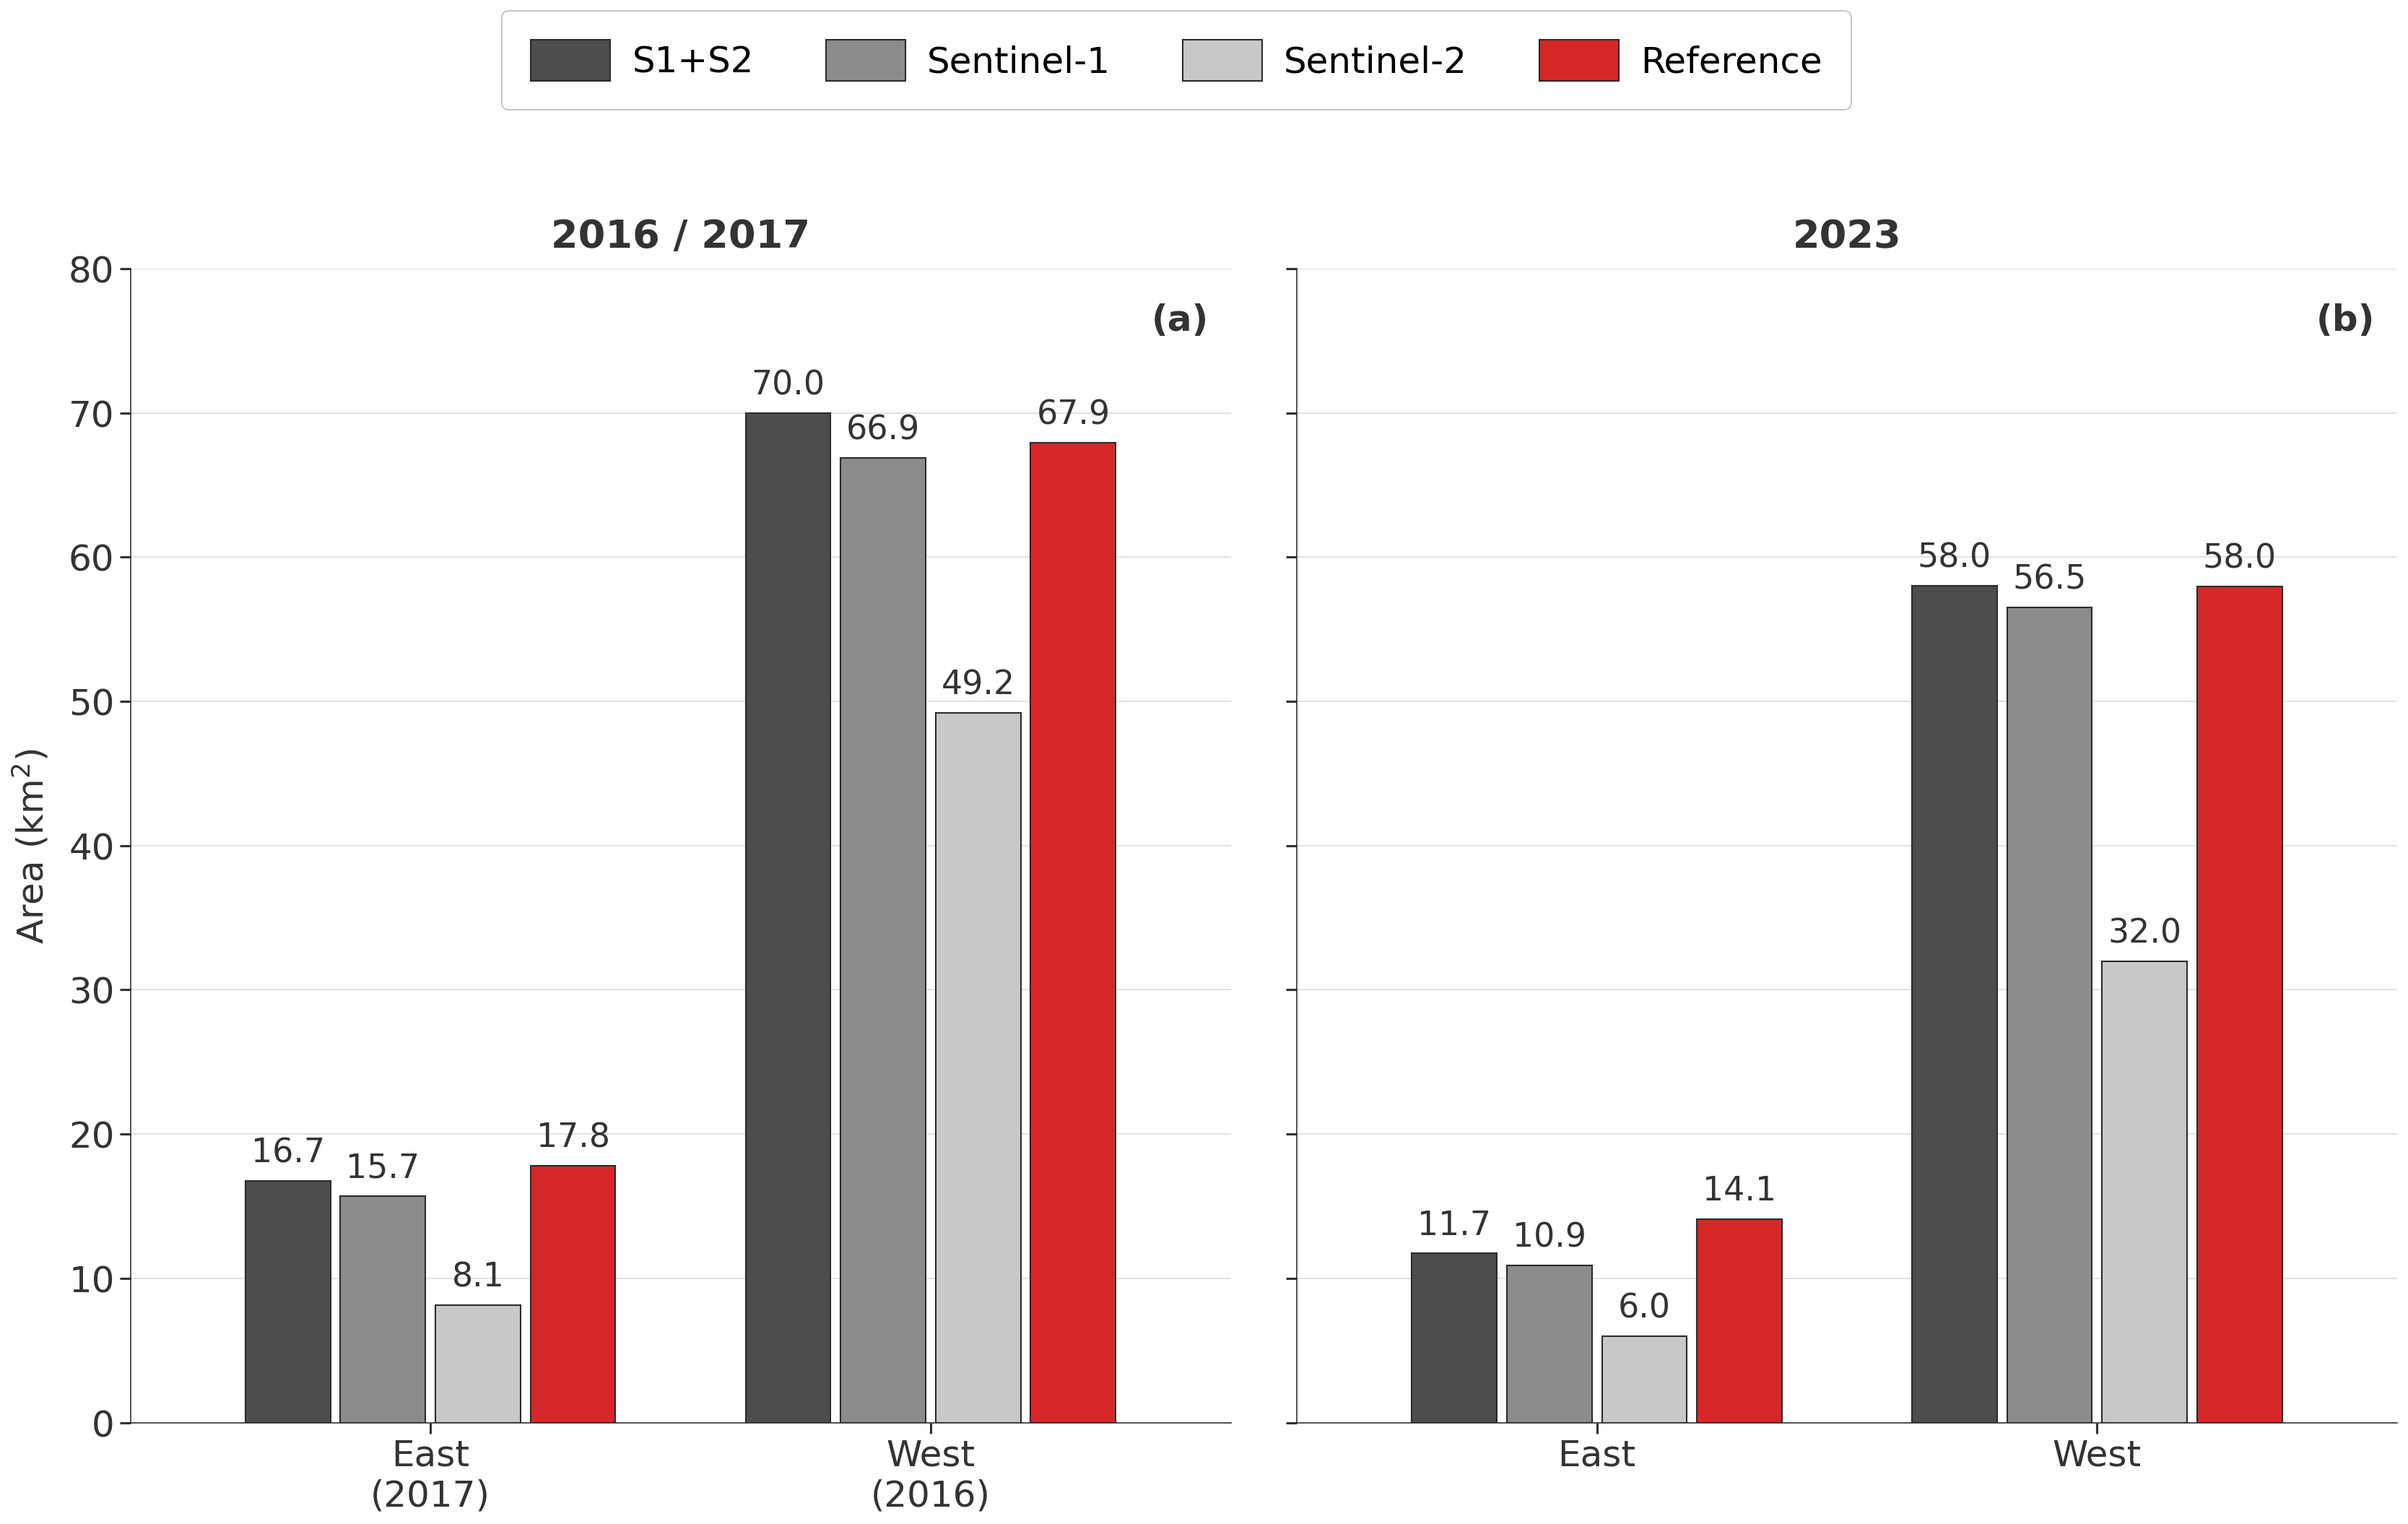

In [14]:
# --------------------------------------------------
# 2. Settings
# --------------------------------------------------
FS_TITLE, FS_LABEL, FS_TICK, FS_LEGEND, FS_VALUE, FS_LETTER = 26, 24, 24, 24, 22, 24

EARLY_YEAR = {'East': 2017, 'West': 2016}
LATE_YEAR = 2023

ref = {'East': (17.802, 14.108), 'West': (67.923, 57.982)}

series = {
    'East': [y1, y3, y5],
    'West': [y2, y4, y6],
}

colors = ['#4D4D4D', '#8C8C8C', '#C8C8C8', '#D62728']

EDGE = '#2B2B2B'
TEXT = '#333333'

sources = ['S1+S2', 'Sentinel-1', 'Sentinel-2', 'Reference']
hatches = ['', '', '', '']

def value_at(s, year):
    idx = np.where(x == year)[0]
    return s[idx[0]] if len(idx) else np.nan

regions = ['East', 'West']
group_pos = np.arange(len(regions))

# Bar geometry
bar_w = 0.17     # width of each bar
gap = 0.02       # space between neighbouring bars
step = bar_w + gap

# --------------------------------------------------
# 3. Figure
# --------------------------------------------------
fig, axes = plt.subplots(1, 2, sharey=True, figsize=(23, 15), dpi=150,
                         gridspec_kw={'wspace': 0.06})

panel_titles = ['2016 / 2017', str(LATE_YEAR)]

for p, ax in enumerate(axes):
    values = [[], [], [], []]
    for region in regions:
        year = EARLY_YEAR[region] if p == 0 else LATE_YEAR
        for k in range(3):
            values[k].append(value_at(series[region][k], year))
        values[3].append(ref[region][p])

    for k, (name, col, hat) in enumerate(zip(sources, colors, hatches)):
        offset = (k - 1.5) * step
        bars = ax.bar(group_pos + offset, values[k], width=bar_w,
                      color=col, edgecolor=EDGE, linewidth=1.0,
                      hatch=hat, label=name, zorder=3)
        for b, v in zip(bars, values[k]):
            if not np.isnan(v):
                ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f'{v:.1f}',
                        ha='center', va='bottom', fontsize=FS_VALUE,
                        color=TEXT)

    if p == 0:
        ticklabels = [f'{r}\n({EARLY_YEAR[r]})' for r in regions]
    else:
        ticklabels = regions

    ax.set_title(panel_titles[p], fontsize=FS_TITLE, fontweight='bold',
                 pad=14, color=TEXT)
    ax.set_xticks(group_pos)
    ax.set_xticklabels(ticklabels)
    ax.set_xlim(-0.6, len(regions) - 0.4)
    ax.tick_params(axis='both', labelsize=FS_TICK, length=7, width=1.5,
                   colors=TEXT)
    ax.grid(True, axis='y', linestyle='-', linewidth=0.8, color='#DDDDDD',
            zorder=0)
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(TEXT)
    ax.text(0.98, 0.97, f'({"ab"[p]})', transform=ax.transAxes,
            fontsize=FS_LETTER, fontweight='bold', ha='right', va='top',
            color=TEXT)

axes[0].set_ylabel(r'Area (km$^2$)', fontsize=FS_LABEL, labelpad=12, color=TEXT)

all_vals = [v for r in regions for s in series[r] for v in s] \
           + [v for r in regions for v in ref[r]]
axes[0].set_ylim(0, np.ceil(np.nanmax(all_vals) / 10) * 10 + 10)

# --------------------------------------------------
# 4. Legend, layout, save
# --------------------------------------------------
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=FS_LEGEND, loc='upper center', ncol=4,
           bbox_to_anchor=(0.5, 0.99), frameon=True, borderpad=0.8,
           columnspacing=2, handlelength=2.2, handleheight=1.4,
           handletextpad=0.6, edgecolor='#BBBBBB')

fig.subplots_adjust(left=0.08, right=0.99, top=0.82, bottom=0.11)

fig.savefig(
    '/mnt/CEPH_PROJECTS/provinzBZ_risk_EO/GlacierOutlines/results_dynamicTresh/sentinel_2016_2023_comparison_area.png',
    dpi=300, bbox_inches='tight', facecolor='white'
)
plt.show()

### Calculate Commission and Omission Error and IoU

In [ ]:
import geopandas as gpd
import pandas as pd
from shapely.geometry import box
from pathlib import Path

VERSION = "v0.4_full"

base_ref = "/mnt/CEPH_PROJECTS/provinzBZ_risk_EO/GlacierOutlines/references/glacier_inventory"
base_res = "/mnt/CEPH_PROJECTS/provinzBZ_risk_EO/GlacierOutlines/results_test/S1_S2"

spatial_extent_west = {"west": 610950, "east": 674650, "south": 5143820, "north": 5206380, "crs": "EPSG:32632"}  # Western South Tyrol glaciers
spatial_extent_east = {"west": 704100, "east": 747040, "south": 5195880, "north": 5219660, "crs": "EPSG:32632"}  # Eastern South Tyrol glaciers
extents = {"west": spatial_extent_west, "east": spatial_extent_east}

# --- load reference ---
# the 2016/2017 file holds both years, so it still has to be split by DATE
ref_2016_2017 = gpd.read_file(f"{base_ref}/SGIhom_2017_v2025.shp")
ref = {
    2016: ref_2016_2017[ref_2016_2017["DATE"] // 10000 == 2016],
    2017: ref_2016_2017[ref_2016_2017["DATE"] // 10000 == 2017],
    2023: gpd.read_file(f"{base_ref}/SGIhom_2023_v2025.shp"),
}

# --- load calculated ---
calc = {
    y: gpd.read_file(f"{base_res}/{y}/s1_s2_glacier_outlines_{y}_{VERSION}_minPatch10000_hole1.shp")
    for y in (2016, 2017, 2023)
}

# --- helpers ---
def clip_to_extent(gdf, ext):
    """Reproject to the extent's CRS, fix geometries, clip to the bounding box."""
    gdf = gdf.to_crs(ext["crs"]).copy()
    gdf["geometry"] = gdf.geometry.make_valid()
    bbox = box(ext["west"], ext["south"], ext["east"], ext["north"])
    clipped = gpd.clip(gdf, bbox)
    return clipped[~clipped.geometry.is_empty]

def iou(a, b):
    a_u = a.geometry.union_all()   # use .unary_union on GeoPandas < 1.0
    b_u = b.geometry.union_all()
    inter = a_u.intersection(b_u).area
    union = a_u.union(b_u).area
    return inter, union, (inter / union if union > 0 else float("nan"))

# --- compute ---
rows = []
for region, ext in extents.items():
    for year in (2016, 2017, 2023):
        r = clip_to_extent(ref[year], ext)
        c = clip_to_extent(calc[year], ext)
        inter, union, score = iou(r, c)
        rows.append({
            "region": region,
            "year": year,
            "ref_area_km2": r.geometry.area.sum() / 1e6,
            "calc_area_km2": c.geometry.area.sum() / 1e6,
            "intersection_km2": inter / 1e6,
            "union_km2": union / 1e6,
            "IoU": score,
            "precision": inter / c.geometry.area.sum(),  # share of your result that is correct
            "recall": inter / r.geometry.area.sum(),     # share of the reference you captured
        })

results = pd.DataFrame(rows).set_index(["region", "year"])
print(results.round(3))

OUT = Path("/mnt/CEPH_PROJECTS/provinzBZ_risk_EO/GlacierOutlines/results_test")

# long format: one row per region/year, all metrics as columns
results.round(4).to_csv(OUT / f"glacier_metrics_long_{VERSION}.csv")

/tmp/ipykernel_2306426/1833572014.py:62: RuntimeWarning: invalid value encountered in scalar divide
  "recall": inter / r.geometry.area.sum(),     # share of the reference you captured
/tmp/ipykernel_2306426/1833572014.py:62: RuntimeWarning: invalid value encountered in scalar divide
  "recall": inter / r.geometry.area.sum(),     # share of the reference you captured


             ref_area_km2  calc_area_km2  intersection_km2  union_km2    IoU  \
region year                                                                    
west   2016        67.923         69.768            64.057     73.608  0.870   
       2017         0.000         68.640             0.000     68.640  0.000   
       2023        57.982         57.173            51.939     63.217  0.822   
east   2016         0.000         17.840             0.000     17.840  0.000   
       2017        17.802         16.648            15.113     19.337  0.782   
       2023        14.108         11.380            10.476     15.012  0.698   

             precision  recall  
region year                     
west   2016      0.918   0.943  
       2017      0.000     NaN  
       2023      0.908   0.896  
east   2016      0.000     NaN  
       2017      0.908   0.849  
       2023      0.921   0.743  


Region  Year  Ref. area (km²)  Calc. area (km²)  Area diff. (%)  IoU  Precision  Recall   F1
  west  2016            67.92             69.77             2.7 0.87       0.92    0.94 0.93
  west  2023            57.98             57.17            -1.4 0.82       0.91    0.90 0.90
  east  2017            17.80             16.65            -6.5 0.78       0.91    0.85 0.88
  east  2023            14.11             11.38           -19.3 0.70       0.92    0.74 0.82

Saved table and figures to .//mnt/CEPH_PROJECTS/provinzBZ_risk_EO/GlacierOutlines/results_test/


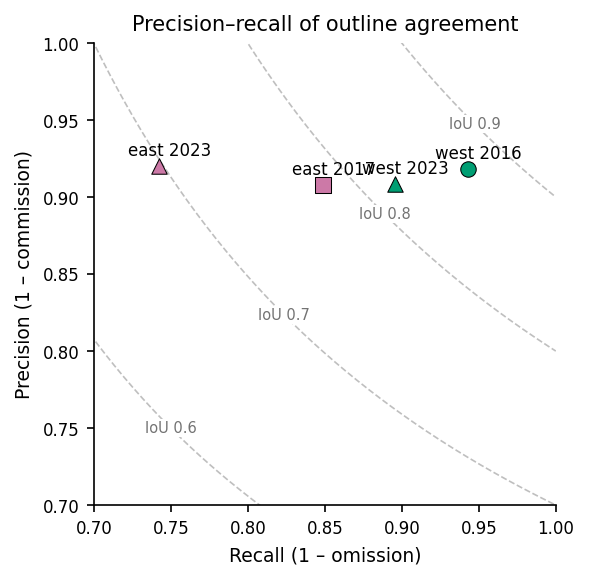

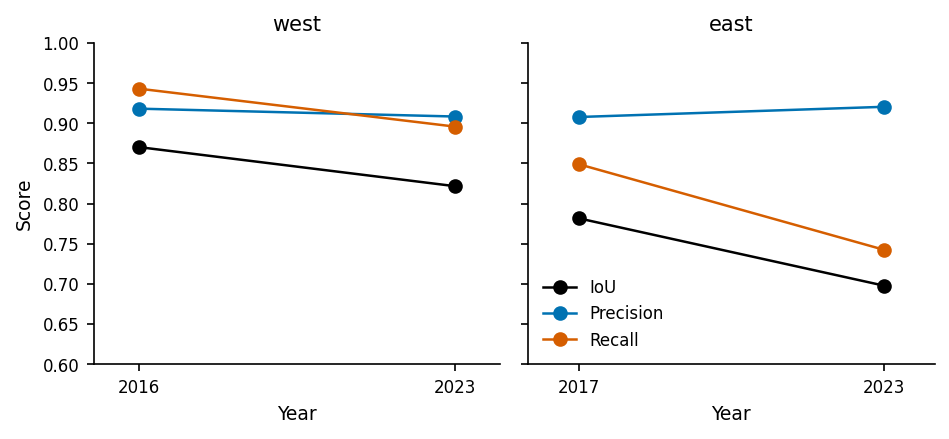

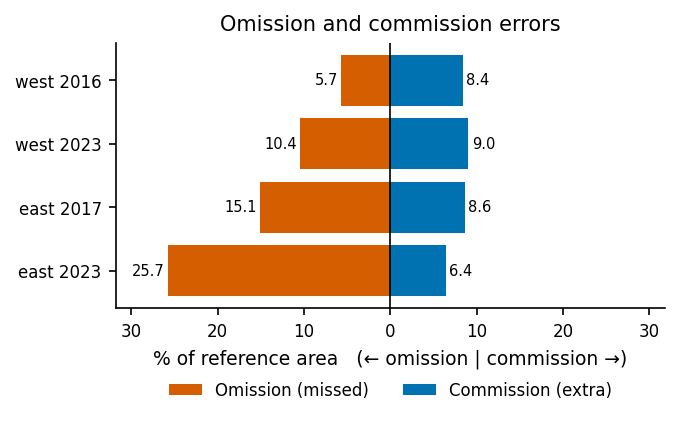

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- data
raw = pd.read_csv(f"{OUT}/glacier_metrics_long_{VERSION}.csv")

# Rows without a reference outline are not valid comparisons -> drop them
df = raw[raw["ref_area_km2"] > 0].copy().reset_index(drop=True)

# ---------------------------------------------------------- derived metrics
df["area_diff_pct"] = (df["calc_area_km2"] - df["ref_area_km2"]) / df["ref_area_km2"] * 100
df["F1"] = 2 * df["IoU"] / (1 + df["IoU"])
# omission / commission as % of reference area
df["omission_pct"] = (df["ref_area_km2"] - df["intersection_km2"]) / df["ref_area_km2"] * 100
df["commission_pct"] = (df["calc_area_km2"] - df["intersection_km2"]) / df["ref_area_km2"] * 100
df["label"] = df["region"] + " " + df["year"].astype(str)

# ------------------------------------------------------------------ table
table = df[["region", "year", "ref_area_km2", "calc_area_km2", "area_diff_pct",
            "IoU", "precision", "recall", "F1"]].copy()
table.columns = ["Region", "Year", "Ref. area (km²)", "Calc. area (km²)",
                 "Area diff. (%)", "IoU", "Precision", "Recall", "F1"]
table = table.round({"Ref. area (km²)": 2, "Calc. area (km²)": 2,
                     "Area diff. (%)": 1, "IoU": 2, "Precision": 2,
                     "Recall": 2, "F1": 2})
table.to_csv(f"{OUT}/table_summary.csv", index=False)
try:
    table.to_latex(f"{OUT}/table_summary.tex", index=False, float_format="%.2f",
                   caption="Agreement between reference and calculated glacier outlines.",
                   label="tab:accuracy")
except Exception as e:  # older pandas versions
    print("LaTeX export skipped:", e)
print(table.to_string(index=False))

# ------------------------------------------------------------------ style
plt.rcParams.update({
    "font.size": 9, "axes.labelsize": 9, "axes.titlesize": 10,
    "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 150,
})
# Okabe-Ito colour-blind-safe palette
C = {"IoU": "#000000", "precision": "#0072B2", "recall": "#D55E00",
     "west": "#009E73", "east": "#CC79A7",
     "omission": "#D55E00", "commission": "#0072B2"}
MARK = {2016: "o", 2017: "s", 2023: "^"}


def save(fig, name):
    fig.savefig(f"{OUT}/{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"{OUT}/{name}.pdf", bbox_inches="tight")


# ------------------------------------------- Fig 1: precision-recall scatter
fig, ax = plt.subplots(figsize=(4.2, 4.0))

r = np.linspace(0.5, 1.0, 400)
for iou in (0.6, 0.7, 0.8, 0.9):
    denom = 1 / iou + 1 - 1 / r
    p = np.where(denom > 0, 1 / denom, np.nan)
    ax.plot(r, p, color="0.75", lw=0.8, ls="--", zorder=1)
    # label each curve where it crosses the precision = recall diagonal
    d = 2 * iou / (1 + iou)
    ax.text(d, d, f"IoU {iou}", fontsize=7, color="0.45", ha="center",
            va="center", zorder=2,
            bbox=dict(fc="white", ec="none", pad=0.8))

# per-point label offsets (points) to avoid overlaps; adjust if data change
OFFSETS = {"West 2016": (0, -14), "West 2023": (0, 9),
           "East 2017": (-10, 9), "East 2023": (0, 9)}

for _, row in df.iterrows():
    ax.scatter(row["recall"], row["precision"], s=55, zorder=3,
               color=C[row["region"]], marker=MARK[row["year"]],
               edgecolor="k", linewidth=0.5)
    ax.annotate(row["label"], (row["recall"], row["precision"]),
                xytext=OFFSETS.get(row["label"], (5, 5)),
                textcoords="offset points", fontsize=8, ha="center")

ax.set_xlim(0.70, 1.0)
ax.set_ylim(0.70, 1.0)
ax.set_xlabel("Recall (1 – omission)")
ax.set_ylabel("Precision (1 – commission)")
ax.set_aspect("equal")
ax.set_title("Precision–recall of outline agreement")
save(fig, "fig_precision_recall")

# ------------------------------------------------ Fig 2: metrics over time
regions = list(df["region"].unique())
fig, axes = plt.subplots(1, len(regions), figsize=(6.4, 3.0), sharey=True)
axes = np.atleast_1d(axes)
for ax, reg in zip(axes, regions):
    sub = df[df["region"] == reg].sort_values("year")
    for metric in ("IoU", "precision", "recall"):
        ax.plot(sub["year"], sub[metric], marker="o", lw=1.2,
                color=C[metric], label=metric.capitalize() if metric != "IoU" else "IoU")
    ax.set_title(reg)
    ax.set_xticks(sub["year"])
    ax.set_xlim(sub["year"].min() - 1, sub["year"].max() + 1)
    ax.set_xlabel("Year")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0.6, 1.0)
axes[-1].legend(frameon=False, loc="lower left")
fig.tight_layout()
save(fig, "fig_metrics_over_time")

# ------------------------------------- Fig 3: omission / commission (diverging)
fig, ax = plt.subplots(figsize=(4.6, 3.0))
y = np.arange(len(df))
ax.barh(y, -df["omission_pct"], color=C["omission"], label="Omission (missed)")
ax.barh(y, df["commission_pct"], color=C["commission"], label="Commission (extra)")
for yi, (o, c) in enumerate(zip(df["omission_pct"], df["commission_pct"])):
    ax.text(-o - 0.4, yi, f"{o:.1f}", ha="right", va="center", fontsize=7)
    ax.text(c + 0.4, yi, f"{c:.1f}", ha="left", va="center", fontsize=7)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(df["label"])
ax.invert_yaxis()
lim = max(df["omission_pct"].max(), df["commission_pct"].max()) + 6
ax.set_xlim(-lim, lim)
ax.set_xlabel("% of reference area   (← omission | commission →)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{abs(v):.0f}"))
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
ax.set_title("Omission and commission errors")
fig.tight_layout()
save(fig, "fig_omission_commission")

print(f"\nSaved table and figures to ./{OUT}/")